# Analisando Grafos do SNAP: G16 `comm-f2f-Resistance`

Trabalho prático de Teoria dos Grafos (IC/UFBA) — Nadson de Santana Sousa, matrícula 224215945.

**Determinação do grafo:** S = 2+2+4+2+1+5+9+4+5 = 34, D = 45 →
(34 × 46) mod 129 = 1564 mod 129 = **16** → **G16 = `comm-f2f-Resistance`**.

Este notebook **não recalcula nada**: ele lê os resultados gerados por `python -m src.executar`
(pasta `results/`) e as figuras (pasta `figures/`). Para refazer as análises, execute o pipeline
descrito no README.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES, FIG, DADOS = RAIZ / "results", RAIZ / "figures", RAIZ / "data" / "processed"


def ler(nome, pasta=RES):
    return json.loads((pasta / nome).read_text())


pd.set_option("display.precision", 4)

## Tratamento dos dados

In [2]:
e = ler("etapas_tratamento.json", DADOS)
pd.DataFrame([
    ("Grafo temporal bruto (com laptop)", e["vertices"], e["arestas_temporais"] + e["arestas_temporais_laptop"]),
    ("Sem laptop", e["vertices"], e["arestas_temporais"]),
    ("Estático (pares ordenados que ocorrem)", e["vertices"], e["pares_estaticos"]),
    ("Após limiar f >= 1/N (arcos)", e["vertices"], e["pares_apos_limiar"]),
    ("Não-direcionado (final)", e["vertices"], e["arestas_nao_dirigidas"]),
], columns=["Etapa", "Vértices", "Arestas"])

,Etapa,Vértices,Arestas
0,Grafo temporal bruto (com laptop),451,3126993
1,Sem laptop,451,2929953
2,Estático (pares ordenados que ocorrem),451,2867
3,Após limiar f >= 1/N (arcos),451,1241
4,Não-direcionado (final),451,951


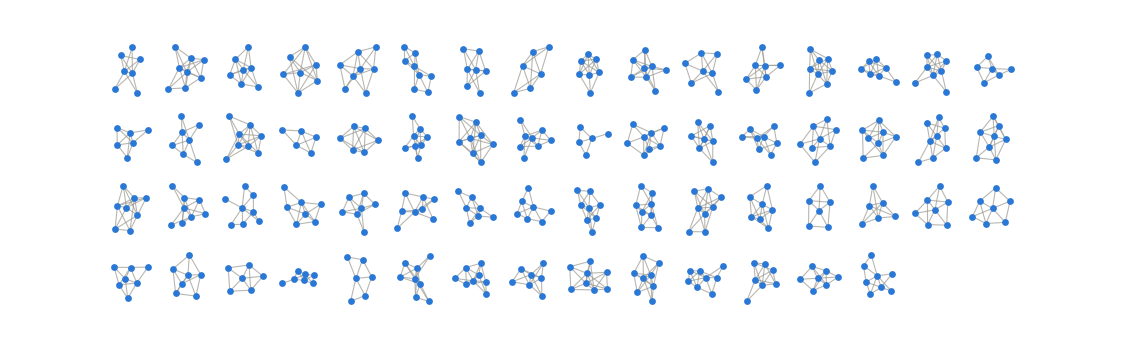

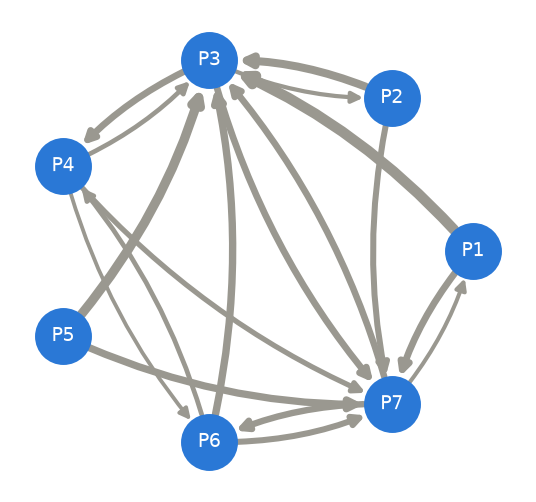

In [3]:
display(Image(FIG / "grafo_completo.png"))
display(Image(FIG / "partida0.png", width=320))

## Parte I: análise estrutural

In [4]:
m = ler("parte1_metricas.json")
chaves = ["vertices", "arestas", "grau_min", "grau_max", "grau_medio", "grau_mediano", "densidade",
          "num_componentes", "tamanho_lcc", "diametro_lcc", "raio_lcc", "caminho_medio_lcc",
          "diametro_max_componentes", "caminho_medio_global", "clusterizacao_media", "triangulos"]
pd.Series({k: m[k] for k in chaves}, name="valor").to_frame()

,valor
vertices,451.0000
arestas,951.0000
grau_min,1.0000
grau_max,7.0000
grau_medio,4.2173
grau_mediano,4.0000
densidade,0.0094
num_componentes,62.0000
tamanho_lcc,8.0000
diametro_lcc,2.0000


Tamanho das componentes -> nº de partidas: {'5': 2, '6': 8, '7': 23, '8': 29}
Distribuição de graus: {'1': 3, '2': 42, '3': 114, '4': 111, '5': 88, '6': 62, '7': 31}


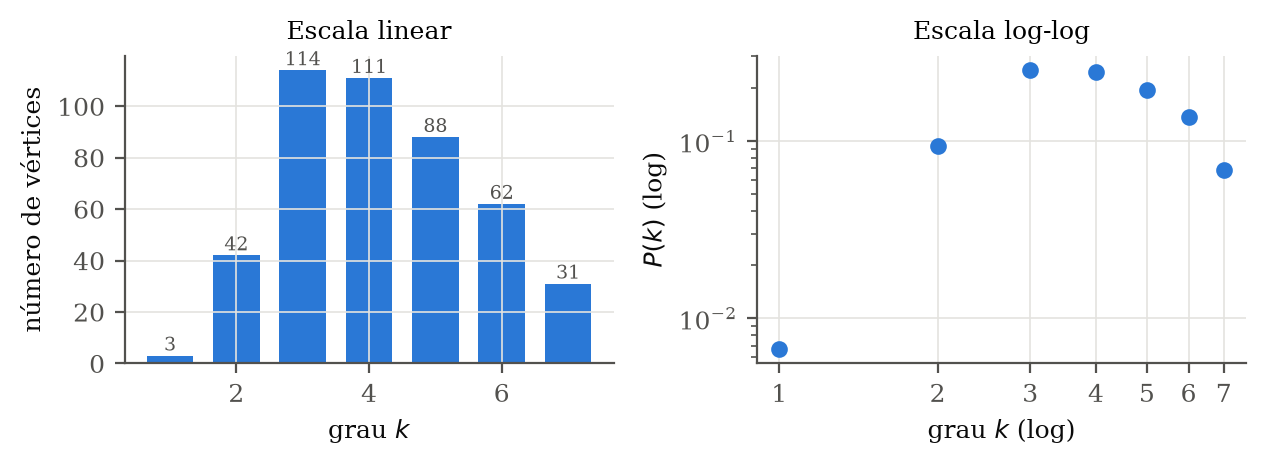

In [5]:
print("Tamanho das componentes -> nº de partidas:", m["tamanhos_componentes_freq"])
print("Distribuição de graus:", m["distribuicao_graus"])
display(Image(FIG / "distribuicao_graus.png"))

## Parte II: algoritmos da disciplina

In [6]:
t = pd.DataFrame(ler("parte2_tempos.json")).T
t["media_ms"] = t["media"].astype(float) * 1000
t["ic_ms"] = [f"[{a * 1000:.3f}; {b * 1000:.3f}]" for a, b in zip(t["ic_inf"], t["ic_sup"])]
t[["complexidade", "n", "distribuicao", "media_ms", "ic_ms"]]

,complexidade,n,distribuicao,media_ms,ic_ms
BFS,O(V+E),50,Z,0.2994,[0.217; 0.381]
DFS,O(V+E),50,Z,0.6920,[0.414; 0.970]
Eulerianidade,O(V+E),50,Z,0.0741,[0.059; 0.089]
Dijkstra (todas as fontes),O(V(V+E)\log V),50,Z,3.6245,[3.348; 3.901]
Bellman-Ford (todas as fontes),O(V^2 E),30,Z,442.9689,[377.529; 508.409]
Floyd-Warshall,O(V^3),10,t,69.9120,[68.672; 71.152]
Floyd-Warshall (numpy),O(V^3),10,t,489.9901,[350.273; 629.707]
Tarjan,O(V+E),50,Z,0.6931,[0.643; 0.743]
Tarjan (pontes e articulações),O(V+E),50,Z,0.7929,[0.738; 0.848]
Prim,O(E\log V),50,Z,0.5575,[0.468; 0.647]


In [7]:
pd.Series(ler("parte2_resultados.json"), name="resultado").to_frame()

,resultado
bfs_visitados,451
dfs_visitados,451
euler_global,"{'tipo': 'nao_euleriano', 'conexo': False, 've..."
euler_por_partida,"{'nao_euleriano': 45, 'circuito': 2, 'caminho'..."
pares_alcancaveis,2870
distancia_media,2.1859
distancia_max,4.8094
par_distancia_max,"[g05_p3, g05_p4]"
dijkstra_bf_fw_concordam,True
fw_numpy_concorda,True


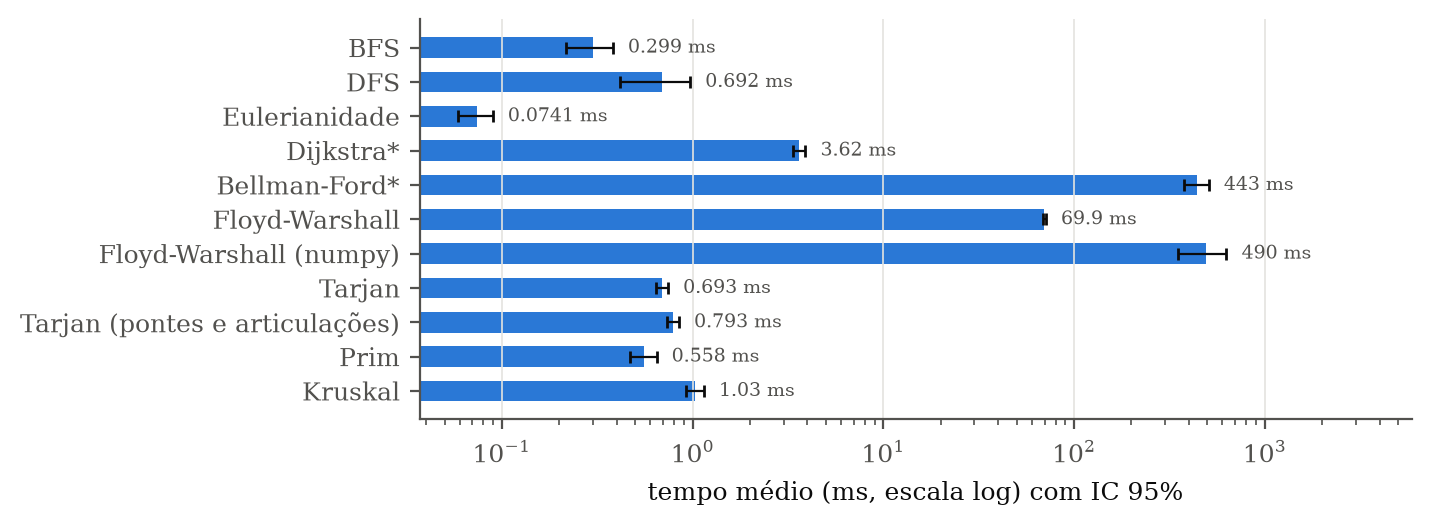

,complexidade,expoente,r2,expoente_v,r2_v
BFS,O(V+E),1.0968,0.9973,1.0845,0.9977
DFS,O(V+E),1.0902,0.9996,1.0777,0.9995
Eulerianidade,O(V+E),0.8943,0.9824,0.8846,0.9835
Dijkstra*,O(V(V+E)\log V),0.4865,0.9971,1.0638,0.9974
Bellman-Ford*,O(V^2E),0.7149,0.9921,2.1329,0.9923
Floyd-Warshall,O(V^3),0.7121,0.9762,2.1364,0.9762
Floyd-Warshall (numpy),O(V^3),1.0711,0.991,3.2133,0.991
Tarjan,O(V+E),1.0396,0.9977,1.0253,0.9975
Pontes/articulações,O(V+E),1.0895,0.9905,1.0765,0.9895
Prim,O(E\log V),0.8754,0.9971,1.0334,0.9962


In [8]:
display(Image(FIG / "tempos.png"))
pd.DataFrame(ler("parte2_escala.json")["ajuste"]).T

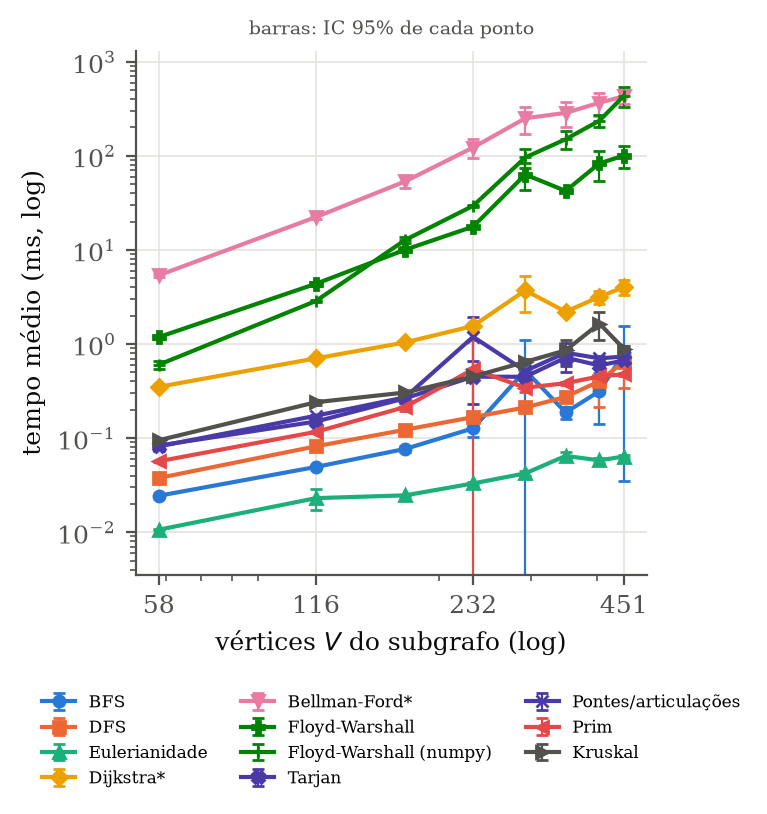

In [9]:
display(Image(FIG / "escala.png", width=420))

## Parte III: propriedades da rede

### Small-world

In [10]:
sw = ler("parte3_small_world.json")["global"]
pd.DataFrame({
    "G(n,m) global": sw["er_global"],
    "G(n,m) por blocos": sw["er_blocos"],
}).T.assign(C_observado=sw["C"], L_observado=sw["L"])

,C_rand,C_rand_dp,L_rand,L_rand_dp,componentes_rand,gamma,lambda,sigma,C_observado,L_observado
"G(n,m) global",0.0082,0.0024,4.3805,0.0321,7.0667,92.1398,0.3059,301.1898,0.7541,1.3401
"G(n,m) por blocos",0.6643,0.0113,1.3451,0.0029,62.4000,1.1353,0.9962,1.1396,0.7541,1.3401


### Lei de potência

Regressão log-log: inclinação 1.26, R² = 0.46
Máxima verossimilhança + KS: {'kmin': 5, 'gamma': 5.883882310232195, 'ks': 0.1316467071314315, 'n_cauda': 181, 'erro_padrao': 0.37938196685933195, 'gamma_aprox': 5.435749483345973}
<k> = 4.22, Var(k) = 2.00, kmax/<k> = 1.66


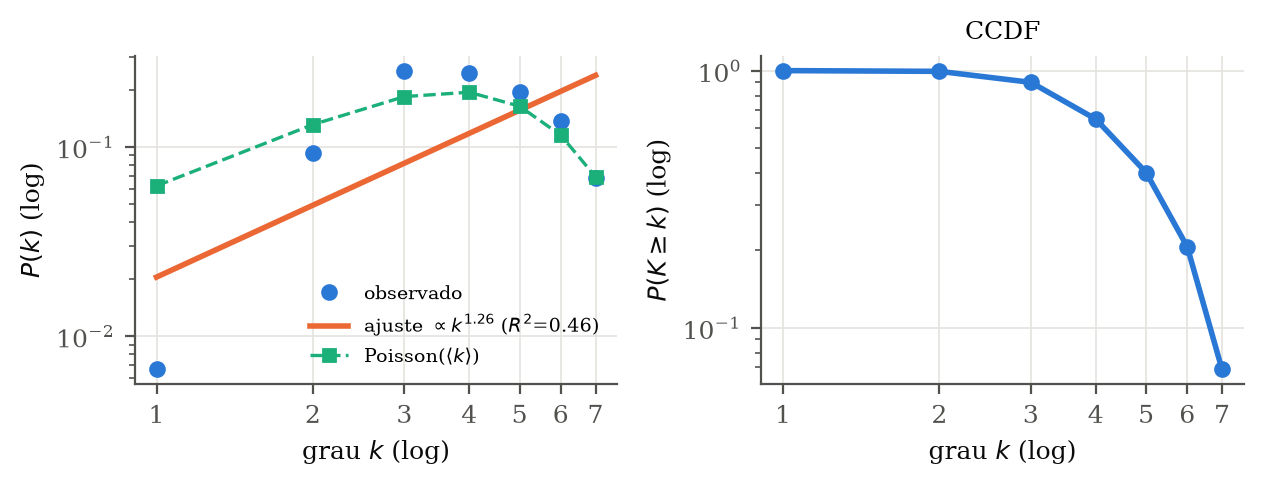

In [11]:
lp = ler("parte3_lei_potencia.json")
print(f"Regressão log-log: inclinação {-lp['gamma_mq']:.2f}, R² = {lp['r2']:.2f}")
print("Máxima verossimilhança + KS:", lp["mv"])
print(f"<k> = {lp['k_medio']:.2f}, Var(k) = {lp['variancia_k']:.2f}, kmax/<k> = {lp['razao_kmax_kmedio']:.2f}")
display(Image(FIG / "lei_potencia.png"))

### Robustez (remoção de 5% dos vértices)

In [12]:
r = ler("parte3_robustez.json")
aleat = pd.DataFrame(r["aleatoria"])
pd.DataFrame({
    "original": r["original"],
    "aleatória (média)": aleat.mean(),
    "aleatória (desvio)": aleat.std(),
    "ataque: grau": r["grau"],
    "ataque: betweenness": r["betweenness"],
    "ataque: PageRank": r["pagerank"],
})

,original,aleatória (média),aleatória (desvio),ataque: grau,ataque: betweenness,ataque: PageRank
A_lcc,8.0000,8.0000,0.0000e+00,8.0000,8.0000,8.0000
A_partidas,1.0000,0.9509,7.6662e-04,0.9446,0.9335,0.9424
B_componentes,62.0000,62.1333,3.4575e-01,65.0000,68.0000,66.0000
C_caminho_medio,1.3401,1.3422,5.9120e-03,1.3948,1.3940,1.3706
C_eficiencia,0.0118,0.0118,5.1456e-05,0.0113,0.0112,0.0114
D_isolados,0.0000,0.0003,8.0593e-04,0.0070,0.0117,0.0093


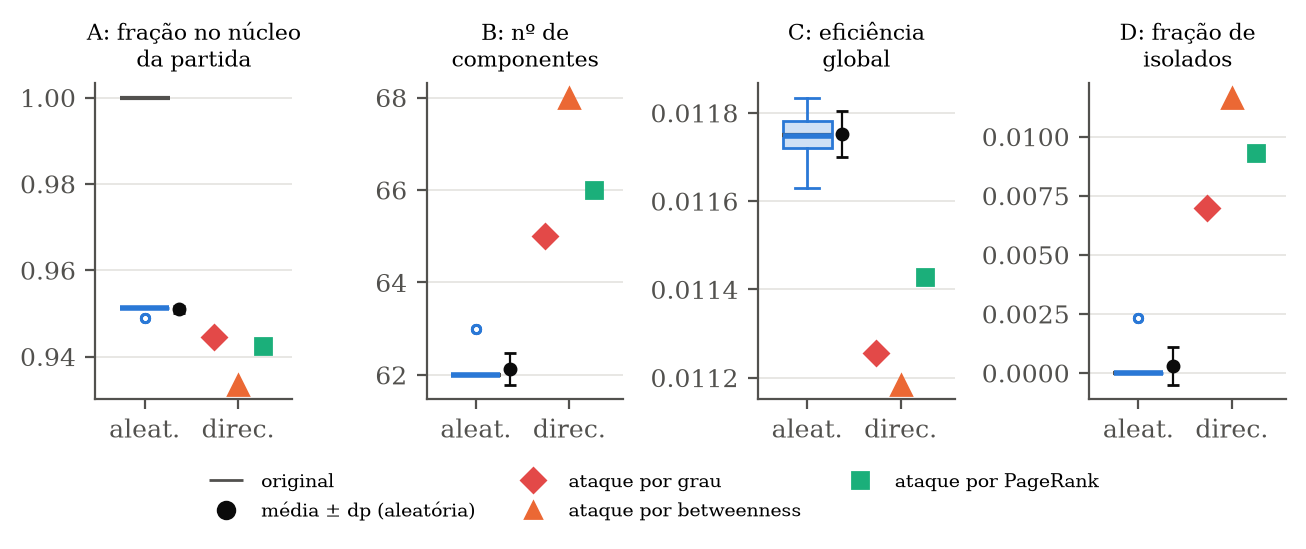

In [13]:
display(Image(FIG / "robustez.png"))

### Extra: modelos clássicos

In [14]:
mod = ler("parte3_modelos.json")
pd.DataFrame({k: v for k, v in mod.items() if k != "parametros"}).T

,arestas,grau_max,var_grau,C,L,componentes
Observado,951.0,7.0,2.0016,0.7541,1.3401,62.0
Erdos-Renyi,951.0,11.5,4.0951,0.0080,4.3955,5.2
Barabasi-Albert,899.0,58.9,24.5905,0.0513,3.6909,1.0
Watts-Strogatz,902.0,6.1,0.3645,0.3707,7.4966,1.0
